# GDGoC UGM Academic Hacker 2026: Prediksi Diagnosis Infeksi Saluran Napas

**Tugas.** Klasifikasi 4 kelas diagnosis (`viral_sinusitis`, `viral_pharyngitis`, `acute_bronchitis`, `strep_pharyngitis`) dari riwayat medis pasien dan data triase. Metrik: **Macro F1**.

**Pendekatan singkat.**
1. **Aturan waktu (point-in-time).** Setiap prediksi hanya boleh memakai data yang sudah tersedia pada `prediction_time`. Ini diuji secara empiris, bukan diasumsikan.
2. **Fitur relasional.** Setiap pasien punya riwayat di banyak tabel (satu-ke-banyak). Riwayat diringkas menjadi satu baris per encounter: jumlah, jarak waktu, kode yang ada, dan nilai numerik terakhir.
3. **Model.** LightGBM dengan pencarian hyperparameter 5-fold CV, dibandingkan dengan baseline Logistic Regression.
4. **Optimasi Macro F1.** Bobot probabilitas per kelas dituning di atas out-of-fold, lalu divalidasi dengan split-half agar tidak optimistik.

**Hasil utama** (dijalankan ulang di notebook ini, lihat bagian 9 sampai 11):
- Baseline Logistic Regression, Macro F1 OOF: **0,6285**
- LightGBM, Macro F1 OOF (argmax): **0,6665**
- LightGBM setelah tuning bobot kelas: **0,6962** (in-sample, optimistik)
- Peningkatan tuning bobot yang diuji split-half: **+0,016**
- Perkiraan skor test: **sekitar 0,68 (±0,02)**

**Struktur notebook.** Bagian 0 sampai 2: persiapan dan data. Bagian 3 sampai 4: aturan waktu dan pembersihan. Bagian 5 sampai 7: fitur dan validasinya. Bagian 8 sampai 11: pemodelan dan evaluasi. Bagian 12 sampai 14: submission, interpretasi, dan keterbatasan.

**Cara menjalankan.** Jalankan semua sel dari atas ke bawah (Run All). Notebook mencari folder data secara otomatis: di Kaggle (`/kaggle/input`) atau di folder induk notebook secara lokal. Waktu eksekusi sekitar 3 menit. Output: `submission.csv` di `/kaggle/working` (Kaggle) atau `output/` di folder notebook (lokal). Kebutuhan paket ada di `requirements.txt`.

## 0. Setup dan konfigurasi

Semua konstanta dikumpulkan di satu sel agar mudah diperiksa. Setiap angka punya alasan yang dijelaskan di bagian terkait.

In [3]:
import os, re, glob, json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             f1_score, log_loss)
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

# --- reproduktibilitas ---
SEED = 42                       # seed utama untuk semua pengacakan
N_SPLITS = 5                    # jumlah fold CV
N_TRIALS = 12                   # jumlah konfigurasi hyperparameter yang dicoba
np.random.seed(SEED)

# --- kolom dan label ---
ID_COLS = ["sample_id", "patient_id", "encounter_id"]   # kolom identitas, bukan fitur
TARGET = "target_class"                                 # nama kolom label
CATEGORICAL = ["gender", "race", "ethnicity", "state", "marital_at_visit"]

# --- aturan pembersihan dan agregasi ---
ONE_SECOND = pd.Timedelta(seconds=1)   # resolusi prediction_time (detik penuh)
MIN_COUNT = 20                         # kode minimal muncul 20 kali agar jadi fitur
VITAL_RANGES = {                       # rentang fisiologis (nilai di luar jadi NaN)
    "Heart rate": (20, 250), "Respiratory rate": (4, 60), "Systolic BP": (50, 260),
    "Diastolic BP": (30, 160), "SpO2": (50, 100), "BMI": (10, 80),
}
OBS_RANGES = {
    "Systolic Blood Pressure": (50, 260), "Diastolic Blood Pressure": (30, 160),
    "Heart rate": (20, 250), "Respiratory rate": (4, 60),
    "Body mass index (BMI) [Ratio]": (10, 80), "Body Weight": (2, 300),
    "Pain severity - 0-10 verbal numeric rating [Score] - Reported": (0, 10),
    "Patient Health Questionnaire 2 item (PHQ-2) total score [Reported]": (0, 6),
}
HIST = {                               # tabel riwayat: (kolom kode, awalan fitur)
    "conditions": ("condition_code", "cond"),
    "medications": ("medication_code", "med"),
    "procedures": ("procedure_code", "proc"),
    "immunizations": ("immunization_code", "imm"),
    "allergies": ("allergy_code", "alg"),
}
TRIAGE_PREFIXES = ("vital__", "sym__", "sym_all_", "sev__", "sev_all_", "cc__")  # untuk uji ablasi

GRID = np.exp(np.linspace(np.log(0.5), np.log(2.0), 21))  # kandidat bobot kelas (0,5 sampai 2)

DECISION_LOG = []     # semua keputusan dan angka pembersihan dicatat di sini (ditampilkan di lampiran)

### Lokasi data dan output

Notebook mencari folder data secara otomatis dengan urutan: folder kerja notebook, folder induknya, lalu lokasi Kaggle. Folder data dikenali dari keberadaan `index_encounters.csv`, `train.csv`, `test.csv`, dan `sample_submission.csv`.

Output (`submission.csv`) disimpan di `output/` di dalam folder kerja, atau di `/kaggle/working` jika dijalankan di Kaggle. Jika deteksi gagal, isi `DATA_DIR_OVERRIDE` di sel berikutnya.

In [4]:
# Jika folder data tidak terdeteksi otomatis, isi path-nya di sini.
# Contoh Windows: DATA_DIR_OVERRIDE = r"C:\Users\nama\Project\gdgoc-ugm-academic-hacker-2026"
DATA_DIR_OVERRIDE = None

REQUIRED_FILES = {"index_encounters.csv", "train.csv", "test.csv", "sample_submission.csv"}

def _subdirs(path):
    """Daftar subfolder langsung di path. Aman dipakai di Windows dan Linux."""
    try:
        return [os.path.join(path, e.name) for e in os.scandir(path) if e.is_dir()]
    except OSError:
        return []

def find_data_dir():
    """
    Cari folder yang berisi semua file data. Urutan pencarian:
      1. Override manual (DATA_DIR_OVERRIDE), jika diisi.
      2. Folder kerja notebook, folder induknya, dan kakek-nya, masing-masing dengan subfolder 2 tingkat.
         Contoh di PyCharm: cwd = .../gdgoc_claude, data = .../gdgoc-ugm-academic-hacker-2026
      3. Lokasi Kaggle (/kaggle/input).
    """
    if DATA_DIR_OVERRIDE:
        if REQUIRED_FILES <= set(os.listdir(DATA_DIR_OVERRIDE)):
            return DATA_DIR_OVERRIDE
        raise FileNotFoundError(f"DATA_DIR_OVERRIDE tidak berisi file yang dibutuhkan: {DATA_DIR_OVERRIDE}")

    here = os.path.abspath(os.getcwd())
    starts = [here, os.path.dirname(here), os.path.dirname(os.path.dirname(here)), "/kaggle/input"]
    for root in starts:
        if not os.path.isdir(root):
            continue
        level1 = _subdirs(root)
        level2 = [g for s in level1 for g in _subdirs(s)]
        for d in [root] + level1 + level2:
            if REQUIRED_FILES <= set(os.listdir(d)):
                return d
    raise FileNotFoundError(
        "Folder data tidak ditemukan. Isi DATA_DIR_OVERRIDE dengan path folder yang berisi "
        "index_encounters.csv, train.csv, test.csv, dan sample_submission.csv."
    )

DATA_DIR = find_data_dir()
OUT_DIR = "/kaggle/working" if os.path.isdir("/kaggle/working") else os.path.join(os.getcwd(), "output")
os.makedirs(OUT_DIR, exist_ok=True)
print("DATA_DIR :", DATA_DIR)
print("OUT_DIR  :", OUT_DIR)

DATA_DIR : C:\INAH-MINE\GEMASTIK-XIX\gdgoc-ugm-academic-hacker-2026
OUT_DIR  : C:\INAH-MINE\GEMASTIK-XIX\gdgoc_claude\output


## 1. Fungsi bantu

Fungsi di sel ini bersifat umum dan bisa dipakai ulang untuk dataset relasional lain. Fungsi dengan awalan yang sama di seluruh notebook mengikuti pola: **pasang cutoff, filter, bersihkan, lalu agregasi**.

Dua aturan yang selalu dijaga:
- Event dianggap tersedia hanya jika terjadi **sebelum** atau **di detik yang sama** dengan cutoff (`apply_cutoff`).
- Nilai yang tidak masuk akal dijadikan `NaN`, bukan ditebak (`apply_valid_range`).

In [5]:
def load_tables(root, exclude=("DATA_DICTIONARY",)):
    """Baca semua CSV di root secara rekursif. Kunci dict = nama file tanpa .csv."""
    tables = {}                                                    # wadah hasil: nama tabel -> DataFrame
    for path in glob.glob(os.path.join(root, "**", "*.csv"), recursive=True):  # cari semua .csv, termasuk subfolder
        name = os.path.splitext(os.path.basename(path))[0]         # ambil nama file tanpa folder dan ekstensi
        if name in exclude:                                        # lewati file metadata
            continue                                               # lanjut ke file berikutnya
        tables[name] = pd.read_csv(path)                           # baca CSV ke DataFrame
    return tables


def parse_ts(series):
    """Ubah string waktu campuran (dengan/tanpa 'Z', dengan/tanpa milidetik) menjadi datetime UTC."""
    return pd.to_datetime(series, utc=True, format="ISO8601", errors="coerce")


def to_float_decimal_comma(series):
    """Angka dengan koma desimal ('18,33') atau titik ('18.33') menjadi float. Selain itu NaN."""
    s = series.astype("string").str.strip()                        # jadikan string dan buang spasi tepi
    s = s.str.replace(",", ".", regex=False)                       # koma -> titik sebagai desimal
    return pd.to_numeric(s, errors="coerce").astype(float)


def parse_amount(x):
    """Pendapatan dengan format campuran: 'USD 122,462', '13.1k', '20,982' (koma = pemisah ribuan)."""
    if pd.isna(x):                                                 # nilai kosong langsung NaN
        return np.nan                                              # kembalikan NaN
    s = str(x).upper().replace("USD", "").replace("$", "").replace(",", "").strip()  # buang USD/$, koma ribuan, spasi
    mult = 1.0                                                     # pengali default
    if s.endswith("K"):                                            # akhiran K berarti ribuan
        mult, s = 1_000.0, s[:-1]                                  # set pengali 1000 dan buang K
    try:                                                           # coba ubah ke angka
        return float(s) * mult                                     # kalikan pengali
    except ValueError:                                             # jika bukan angka
        return np.nan


def clean_col_names(df):
    """LightGBM menolak karakter seperti spasi, [ ], :, koma pada nama kolom. Ganti semuanya dengan _."""
    df = df.copy()                                                 # jangan ubah DataFrame asli
    seen, names = {}, []                                           # seen: hitung nama yang sudah dipakai
    for c in df.columns:                                           # proses tiap nama kolom
        base = re.sub(r"[^0-9A-Za-z_]+", "_", str(c)).strip("_")   # regex ganti karakter ilegal dengan _
        n = seen.get(base, 0)                                      # sudah berapa kali nama dasar ini muncul
        seen[base] = n + 1                                         # tambah hitungan
        names.append(base if n == 0 else f"{base}_{n + 1}")        # tabrakan -> beri akhiran _2, _3, ...
    df.columns = names                                             # pasang nama baru
    assert df.columns.is_unique                                    # pengaman terakhir: pasti unik
    return df


def attach_cutoff(df, index_df, key):
    """Tambah kolom 'cutoff' (prediction_time) ke tiap baris lewat join pada key."""
    lookup = index_df[[key, "cutoff"]]                             # ambil hanya kunci dan cutoff dari tabel indeks
    return df.merge(lookup, on=key, how="inner", validate="many_to_one")


def apply_cutoff(df, time_col, log, name, strict=False):
    """
    Simpan hanya baris yang sudah tersedia pada cutoff.
      strict=False : tersedia jika ts < cutoff + 1 detik  (dipakai untuk pipeline)
      strict=True  : tersedia jika ts < cutoff            (hanya untuk diagnosis)
    Setiap pemanggilan menambah satu catatan ke `log` (list of dict).
    """
    ts = parse_ts(df[time_col])                                    # ubah kolom waktu ke datetime UTC
    limit = df["cutoff"] if strict else df["cutoff"] + ONE_SECOND  # pilih batas: cutoff atau cutoff+1 detik
    keep = ts < limit                                              # True jika event sudah tersedia (NaT -> False)
    log.append({                                                   # catat keputusan agar bisa ditulis di laporan
        "table": name,                                             # nama tabel
        "time_col": time_col,                                      # kolom waktu yang dipakai
        "mode": "strict(<cutoff)" if strict else "same-second(<cutoff+1s)",  # aturan yang dipakai
        "rows_in": int(len(df)),                                   # jumlah baris sebelum filter
        "kept": int(keep.sum()),                                   # baris yang lolos
        "dropped": int((~keep).sum()),                             # baris yang dibuang
        "ts_unparsed": int(ts.isna().sum()),                       # waktu yang gagal diparse
    })
    out = df.loc[keep].copy()                                      # ambil baris yang lolos
    out["_ts"] = ts[keep]                                          # simpan waktu event sebagai datetime
    out["_days_before"] = ((out["cutoff"] - out["_ts"]).dt.total_seconds() / 86400).clip(lower=0)  # jarak hari ke cutoff (>=0)
    return out


def apply_valid_range(df, name_col, value_col, ranges, log, name):
    """Nilai di luar [min, max] untuk nama tertentu dijadikan NaN. Nilai tidak diperbaiki/ditebak."""
    df = df.copy()                                                 # jangan ubah input
    for label, (lo, hi) in ranges.items():                         # tiap konsep punya batas sendiri
        m = (df[name_col] == label) & df[value_col].notna()        # baris dengan label ini dan nilai ada
        out = m & ((df[value_col] < lo) | (df[value_col] > hi))    # yang berada di luar batas
        log.append({"table": name, "check": f"range:{label}", "out_of_range_set_nan": int(out.sum()), "bounds": (lo, hi)})
        df.loc[out, value_col] = np.nan                            # buang nilai tidak masuk akal
    return df


def vocab_from(df, code_col, min_count):
    """Daftar kode yang muncul minimal min_count kali. Dihitung dari fitur (tanpa label), aman untuk train+test."""
    vc = df[code_col].value_counts()                               # hitung kemunculan tiap kode
    return set(vc[vc >= min_count].index)


def agg_recency(df, key, prefix):
    """Jumlah event sebelum cutoff, dan jarak hari ke event terbaru."""
    g = df.groupby(key)                                            # kelompokkan per pasien/encounter
    return pd.DataFrame({
        f"{prefix}_n": g.size(),                                   # jumlah baris event
        f"{prefix}_days_since_last": g["_days_before"].min(),      # event terbaru = jarak hari terkecil
    })


def agg_code_bag(df, key, code_col, prefix, vocab):
    """Satu kolom biner per kode: 1 jika kode itu muncul untuk key tersebut sebelum cutoff."""
    sub = df[df[code_col].isin(vocab)]                             # ambil hanya kode yang masuk vocab
    if sub.empty:                                                  # jika kosong, kembalikan tabel kosong
        return pd.DataFrame(index=pd.Index([], name=key))
    ct = pd.crosstab(sub[key], sub[code_col])                      # tabel silang: baris key, kolom kode, isi jumlah
    ct = (ct > 0).astype(np.int8)                                  # ubah jumlah menjadi 0/1 (ada/tidak)
    ct.columns = [f"{prefix}__{c}" for c in ct.columns]            # beri awalan supaya nama kolom jelas asal tabelnya
    return ct


def agg_numeric_by_code(df, key, code_col, value_col, prefix, vocab, stats=("last", "mean")):
    """Nilai numerik per kode. stats: last (terakhir sebelum cutoff), mean, min, max, dll."""
    sub = df[df[code_col].isin(vocab) & df[value_col].notna()]     # hanya kode di vocab dan nilai tidak kosong
    sub = sub.sort_values("_ts")                                   # urutkan waktu supaya 'last' benar
    parts = []                                                     # wadah hasil tiap statistik
    for st in stats:                                               # ulangi untuk tiap jenis statistik
        grouped = sub.groupby([key, code_col])[value_col]          # kelompok (key, kode)
        w = getattr(grouped, st)().unstack(code_col)               # hitung statistik lalu jadikan kolom per kode
        w.columns = [f"{prefix}__{c}__{st}" for c in w.columns]    # beri nama: prefix__kode__statistik
        parts.append(w)                                            # simpan
    return pd.concat(parts, axis=1) if parts else pd.DataFrame()


def explode_tokens(df, key, col, sep=",", strip_prefix=None):
    """Teks bebas 'Reports: Fever, Throat' menjadi satu baris per token (key, token)."""
    s = df[col].astype("string")                                   # pastikan tipe string
    if strip_prefix:                                               # buang awalan tetap jika ada
        s = s.str.replace(strip_prefix, "", regex=False)
    tmp = df[[key]].copy()                                         # ambil kolom key saja
    tmp["token"] = s.str.split(sep)                                # pecah teks berdasarkan pemisah
    tmp = tmp.explode("token").dropna(subset=["token"]).reset_index(drop=True)  # satu token per baris; reset index agar unik
    tmp["token"] = tmp["token"].astype("string").str.strip().str.lower()  # rapikan spasi dan huruf kecil
    return tmp[tmp["token"].fillna("") != ""]


def to_entity_level(part, universe, level):
    """Ubah fitur level pasien menjadi level encounter (satu pasien = satu encounter di tabel indeks)."""
    if level == "encounter":                                       # sudah level encounter
        return part                                                # kembalikan apa adanya
    aligned = part.reindex(universe["patient_id"].values)          # urutkan baris mengikuti urutan universe
    aligned.index = universe["encounter_id"].values                # ganti index menjadi encounter_id
    return aligned

## 2. Memuat data dan memahami grain

**Grain** adalah apa yang diwakili satu baris di setiap tabel. Ini menentukan bagaimana tabel digabungkan. Tabel indeks dan sampel (train/test) punya satu baris per encounter. Tabel lain bisa punya banyak baris per pasien atau per encounter.

In [6]:
tables = load_tables(DATA_DIR)
print(f"{len(tables)} tabel dimuat\n")

rows = []
for name, df in sorted(tables.items()):
    keys = [k for k in ["patient_id", "encounter_id", "history_encounter_id"] if k in df.columns]
    uniq = {k: df[k].nunique() for k in keys}
    rows.append({"tabel": name, "baris": len(df), "kolom": df.shape[1],
                 "kunci_unik": ", ".join(f"{k}={v}" for k, v in uniq.items())})
grain = pd.DataFrame(rows)
grain

16 tabel dimuat



,tabel,baris,kolom,kunci_unik
0,allergies,2,10,"patient_id=1, history_encounter_id=1"
1,conditions,3583,5,"patient_id=2222, history_encounter_id=2222"
2,immunizations,1802,5,"patient_id=1314, history_encounter_id=1314"
3,index_encounters,5000,3,"patient_id=5000, encounter_id=5000"
4,medications,3467,5,"patient_id=2001, history_encounter_id=2001"
5,observations,55648,9,"patient_id=1895, history_encounter_id=1895"
6,patients,5000,10,patient_id=5000
7,presenting_complaints,5000,3,"patient_id=5000, encounter_id=5000"
8,previous_encounter,4471,7,"patient_id=4471, history_encounter_id=4471"
9,procedures,17024,6,"patient_id=3111, history_encounter_id=3111"


**Pengamatan.** Tabel indeks berisi tepat satu encounter per pasien (5.000 pasien unik), dan train plus test membagi 5.000 encounter tersebut. Semua tabel riwayat satu-ke-banyak, sehingga harus diringkas sebelum digabung.

In [7]:
idx = tables["index_encounters"]
assert idx["encounter_id"].is_unique and idx["patient_id"].is_unique, "satu encounter per pasien diharapkan"
print("Distribusi kelas di train:")
print(tables["train"][TARGET].value_counts(normalize=True).round(3).to_string())

Distribusi kelas di train:
target_class
viral_sinusitis      0.411
viral_pharyngitis    0.274
acute_bronchitis     0.261
strep_pharyngitis    0.054


## 3. Aturan waktu (point-in-time)

Model hanya boleh memakai data yang sudah tersedia pada `prediction_time`. Kalau tidak, model tampak akurat saat pengembangan tetapi gagal saat dipakai.

Timestamp `prediction_time` punya resolusi detik. Pertanyaannya: apakah data triase dicatat *sebelum* prediksi, atau di waktu yang sama? Kita uji secara empiris.

In [8]:
def build_universe(t):
    """Ambil tabel indeks dan turunkan cutoff = prediction_time dalam resolusi detik."""
    idx = t["index_encounters"][["patient_id", "encounter_id", "prediction_time"]].copy()  # kolom yang dibutuhkan
    idx["cutoff"] = parse_ts(idx["prediction_time"]).dt.floor("s")                     # potong ke detik penuh
    assert idx["cutoff"].notna().all(), "ada prediction_time yang gagal diparse"            # pengaman
    assert idx["encounter_id"].is_unique and idx["patient_id"].is_unique                  # satu encounter per pasien
    return idx

In [9]:
universe = build_universe(tables)
print("Universe:", universe.shape, "| cutoff unik:", universe["cutoff"].nunique())

# Uji resolusi: apakah timestamp triase = prediction_time setelah dipotong ke detik?
print("\nUji floor(timestamp, detik) == prediction_time:")
for name, col in [("triage_vitals", "measured_at"), ("triage_symptoms", "observed_at"),
                  ("triage_symptom_severity", "observed_at")]:
    d = tables[name].merge(universe[["encounter_id", "cutoff"]], on="encounter_id", how="inner")
    ts = parse_ts(d[col])
    share = (ts.dt.floor("s") == d["cutoff"]).mean() * 100
    print(f"  {name:26s} {share:6.2f}% baris cocok")

Universe: (5000, 4) | cutoff unik: 5000

Uji floor(timestamp, detik) == prediction_time:
  triage_vitals              100.00% baris cocok
  triage_symptoms            100.00% baris cocok
  triage_symptom_severity    100.00% baris cocok


**Kesimpulan uji.** Seluruh timestamp triase, setelah dipotong ke detik, sama persis dengan `prediction_time` (100% baris). Jadi triase dicatat **pada saat prediksi**, bukan sesudahnya. Selisihnya hanya sub-detik.

Aturan strict (`waktu < cutoff`) akan membuang semua data triase karena selisih itu. Sel berikut membuktikannya dengan angka. Aturan yang dipakai adalah `waktu < cutoff + 1 detik`.

In [10]:
# Perbandingan dua aturan untuk semua tabel yang bertimestamp
comp = []
for name, col, key in [("triage_vitals", "measured_at", "encounter_id"),
                       ("triage_symptoms", "observed_at", "encounter_id"),
                       ("triage_symptom_severity", "observed_at", "encounter_id"),
                       ("conditions", "recorded_at", "patient_id"),
                       ("observations", "observed_at", "patient_id"),
                       ("previous_encounter", "history_start", "patient_id")]:
    d = attach_cutoff(tables[name], universe, key)
    n_strict = len(apply_cutoff(d, col, DECISION_LOG, name, strict=True))
    n_same = len(apply_cutoff(d, col, DECISION_LOG, name, strict=False))
    comp.append({"tabel": name, "baris": len(d), "lolos aturan strict": n_strict,
                 "lolos same-second (dipakai)": n_same})
pd.DataFrame(comp)

,tabel,baris,lolos aturan strict,lolos same-second (dipakai)
0,triage_vitals,30000,0,30000
1,triage_symptoms,19065,0,19065
2,triage_symptom_severity,16594,0,16594
3,conditions,3583,3583,3583
4,observations,55648,55648,55648
5,previous_encounter,4471,4471,4471


**Keputusan.** Aturan `same-second` dipakai untuk semua tabel. Tabel riwayat tidak terpengaruh karena tidak punya baris di atas cutoff. Tabel triase hanya lolos dengan aturan ini, sehingga keputusannya penting.

## 4. Pembersihan: format angka, satuan, dan rentang

Data dibersihkan dengan tiga aturan:
- **Koma desimal** (`18,33`) diubah menjadi titik. Berlaku untuk vital dan observasi.
- **Satuan** disamakan: SpO2 pecahan dikali 100, dan tekanan darah kPa dikali 7,50062 untuk menjadi mmHg.
- **Nilai di luar rentang klinis** dijadikan `NaN`, bukan diperbaiki dengan tebakan.

Pendapatan punya aturan terpisah karena koma di sana adalah pemisah ribuan.

In [11]:
v = tables["triage_vitals"]
print("Pasangan nama vital dan satuan:")
print(pd.crosstab(v["vital_name"], v["unit"]).to_string())
print("\nNilai vital yang berkoma desimal:", int(v["value"].astype("string").str.contains(",", na=False).sum()))

Pasangan nama vital dan satuan:
unit                 %  /min  beats/min  breaths/min  fraction  kPa  kg/m2  mmHg
vital_name                                                                      
BMI                  0     0          0            0         0    0   5000     0
Diastolic BP         0     0          0            0         0  317      0  4683
Heart rate           0  4333        667            0         0    0      0     0
Respiratory rate     0  4338          0          662         0    0      0     0
SpO2              4569     0          0            0       431    0      0     0
Systolic BP          0     0          0            0         0  301      0  4699

Nilai vital yang berkoma desimal: 112


**Pengamatan.** Beberapa satuan tampak berbeda untuk konsep yang sama, misalnya SpO2 dengan `%` dan `fraction`. Pembersihan dilakukan di sel-sel berikutnya dan setiap jumlah nilai yang diubah tercatat di log.

## 5. Membangun fitur per sumber

Setiap sumber data punya fungsi sendiri, karena struktur dan maknanya berbeda. Fungsi-fungsi ini dipanggil di sel 6.

In [12]:
def demographics(t, u, log):
    """Usia, gender, ras, dll. Pendapatan di-parse. city & county dibuang (kardinalitas tinggi)."""
    p = t["patients"].copy()                                                # salinan tabel pasien
    p["income"] = p["income_at_visit"].map(parse_amount)                  # parse format campuran menjadi angka
    p["log_income"] = np.log1p(p["income"])                                  # log agar skala besar tidak mendominasi
    log.append({"table": "patients", "check": "income_unparsed", "count": int(p["income"].isna().sum() - p["income_at_visit"].isna().sum())})
    log.append({"table": "patients", "decision": "city & county dibuang: kardinalitas tinggi, rawan overfit"})
    keep = ["patient_id", "age_at_visit", "log_income"] + CATEGORICAL     # kolom yang dipakai
    p = p[keep].merge(u[["patient_id"]], on="patient_id")                    # batasi ke pasien di universe
    return p.set_index("patient_id"), "patient", "other"


def convert_vital_units(v, log):
    """Samakan satuan: SpO2 'fraction' -> persen, tekanan darah 'kPa' -> mmHg."""
    v = v.copy()                                                              # jangan ubah input
    m = (v["vital_name"] == "SpO2") & (v["unit"] == "fraction")               # saturasi yang ditulis pecahan
    log.append({"table": "triage_vitals", "check": "SpO2 fraction -> persen", "rows": int(m.sum())})
    v.loc[m, "value"] = v.loc[m, "value"] * 100                               # 0.96 -> 96
    m = v["vital_name"].isin(["Systolic BP", "Diastolic BP"]) & (v["unit"] == "kPa")  # tekanan dalam kPa
    log.append({"table": "triage_vitals", "check": "BP kPa -> mmHg", "rows": int(m.sum())})
    v.loc[m, "value"] = v.loc[m, "value"] * 7.50062                           # 1 kPa = 7,50062 mmHg
    return v


def triage(t, u, log):
    """Fitur triase: vital, gejala, severity, dan keluhan utama. Semuanya level encounter."""
    out = []                                                                  # wadah hasil (df, level, jenis)

    # --- vital signs ---
    v = attach_cutoff(t["triage_vitals"], u, "encounter_id")               # pasang cutoff lewat encounter
    v = apply_cutoff(v, "measured_at", log, "triage_vitals")               # simpan yang tersedia pada cutoff
    v["value"] = to_float_decimal_comma(v["value"])                        # '18,33' -> 18.33
    v = convert_vital_units(v, log)                                           # samakan satuan
    v = apply_valid_range(v, "vital_name", "value", VITAL_RANGES, log, "triage_vitals")  # buang nilai mustahil
    out.append((agg_numeric_by_code(v, "encounter_id", "vital_name", "value", "vital",
                                       set(v["vital_name"].unique()), stats=("last",)), "encounter", "num"))

    # --- gejala (ada/tidak) ---
    s = attach_cutoff(t["triage_symptoms"], u, "encounter_id")
    s = apply_cutoff(s, "observed_at", log, "triage_symptoms")
    vocab = vocab_from(s, "symptom_concept", MIN_COUNT)                    # gejala yang cukup sering
    out.append((agg_code_bag(s, "encounter_id", "symptom_concept", "sym", vocab), "encounter", "bag"))
    out.append((agg_recency(s, "encounter_id", "sym_all"), "encounter", "count"))

    # --- severity (skor 0-100 per gejala) ---
    sv = attach_cutoff(t["triage_symptom_severity"], u, "encounter_id")
    sv = apply_cutoff(sv, "observed_at", log, "triage_symptom_severity")
    sv["severity_score"] = pd.to_numeric(sv["severity_score"], errors="coerce")
    vocab = vocab_from(sv[sv["severity_score"].notna()], "symptom_concept", MIN_COUNT)
    out.append((agg_numeric_by_code(sv, "encounter_id", "symptom_concept", "severity_score",
                                       "sev", vocab, stats=("max",)), "encounter", "num"))
    g = sv.groupby("encounter_id")["severity_score"]                          # agregat keseluruhan
    out.append((pd.DataFrame({"sev_all_max": g.max(), "sev_all_mean": g.mean()}), "encounter", "num"))

    # --- keluhan utama (teks bebas) ---
    pc = t["presenting_complaints"]                                           # tidak punya timestamp
    pc = pc[pc["encounter_id"].isin(u["encounter_id"])]                       # pastikan encounter ada di universe
    log.append({"table": "presenting_complaints",
                "decision": "tanpa timestamp: dianggap dicatat saat triase (encounter indeks). Asumsi, lihat log."})
    tok = explode_tokens(pc, "encounter_id", "presenting_complaints_text",
                            sep=",", strip_prefix="Reports:")                 # 'Reports: Fever, Throat' -> token
    vocab = vocab_from(tok, "token", MIN_COUNT)
    out.append((agg_code_bag(tok, "encounter_id", "token", "cc", vocab), "encounter", "bag"))
    return out


def history(t, u, log):
    """Kondisi, obat, prosedur, imunisasi, alergi: jumlah, jarak waktu, dan kode yang ada."""
    out = []
    for name, (code, pre) in HIST.items():                                    # ulangi untuk tiap tabel riwayat
        h = attach_cutoff(t[name], u, "patient_id")                        # pasang cutoff lewat pasien
        h = apply_cutoff(h, "recorded_at", log, name)                      # buang yang setelah cutoff
        vocab = vocab_from(h, code, MIN_COUNT)                             # kode yang cukup sering
        out.append((agg_recency(h, "patient_id", pre), "patient", "count"))
        out.append((agg_code_bag(h, "patient_id", code, pre, vocab), "patient", "bag"))
    return out


def previous_encounters(t, u, log):
    """Riwayat kunjungan sebelumnya: jumlah, jarak waktu, durasi rata-rata, dan jenisnya."""
    pe = attach_cutoff(t["previous_encounter"], u, "patient_id")
    pe = apply_cutoff(pe, "history_start", log, "previous_encounter")      # aturan utama: waktu mulai
    stop = parse_ts(pe["history_stop"])                                    # waktu selesai
    log.append({"table": "previous_encounter", "check": "history_stop melewati cutoff",
                "count": int((stop >= pe["cutoff"] + ONE_SECOND).sum())})  # pengaman kedua
    pe["dur_days"] = (stop[pe.index] - pe["_ts"]).dt.total_seconds() / 86400   # durasi kunjungan dalam hari
    out = [(agg_recency(pe, "patient_id", "prev"), "patient", "count")]
    out.append((pe.groupby("patient_id")["dur_days"].mean().rename("prev_dur_days_mean").to_frame(), "patient", "num"))
    vocab = vocab_from(pe, "history_type_code", MIN_COUNT)
    out.append((agg_code_bag(pe, "patient_id", "history_type_code", "prev", vocab), "patient", "bag"))
    return out


def observations(t, u, log):
    """Numerik per kode (last, mean) dan teks sebagai token 'kode=nilai'."""
    out = []
    ob = attach_cutoff(t["observations"], u, "patient_id")
    ob = apply_cutoff(ob, "observed_at", log, "observations")
    out.append((agg_recency(ob, "patient_id", "obs"), "patient", "count"))

    num = ob[ob["value_type"] == "numeric"].copy()                            # bagian numerik
    num["value"] = to_float_decimal_comma(num["value"])                    # koma desimal -> titik
    num = apply_valid_range(num, "observation_name", "value", OBS_RANGES, log, "observations")
    numok = num[num["value"].notna()]                                         # hanya nilai yang valid
    vocab = vocab_from(numok, "observation_code", MIN_COUNT)
    out.append((agg_numeric_by_code(numok, "patient_id", "observation_code", "value", "obsnum",
                                       vocab, stats=("last", "mean")), "patient", "num"))

    txt = ob[(ob["value_type"] == "text") & ob["value"].notna()].copy()       # bagian teks
    txt["token"] = txt["observation_code"].astype(str) + "=" + txt["value"].astype(str).str.strip().str.lower()
    vocab = vocab_from(txt, "token", MIN_COUNT)
    out.append((agg_code_bag(txt, "patient_id", "token", "obstxt", vocab), "patient", "bag"))
    return out


def assemble(u, parts):
    """Gabungkan semua bagian ke level encounter, lalu isi nilai kosong sesuai jenis fitur."""
    frames, bag_or_count = [], []                                             # daftar bagian dan kolom yang diisi 0
    for df, level, kind in parts:
        aligned = to_entity_level(df, u, level)                            # semua ke level encounter
        frames.append(aligned)
        if kind in ("bag", "count"):                                          # bag/count: tidak ada = 0
            bag_or_count.extend(aligned.columns)
    feat = pd.concat(frames, axis=1)                                          # gabung kolom berdasarkan index
    feat = feat.loc[:, ~feat.columns.duplicated()]                            # buang kolom kembar
    feat = feat.reindex(u["encounter_id"].values)                             # urutkan dan pastikan semua encounter ada
    feat[[c for c in bag_or_count if c in feat.columns]] = feat[[c for c in bag_or_count if c in feat.columns]].fillna(0)
    feat.index.name = "encounter_id"
    return feat.reset_index().copy()

## 6. Jalankan pembangunan fitur

Setiap bagian menghasilkan tuple `(tabel, level, jenis)`. Level menunjukkan apakah fitur per pasien atau per encounter. Jenis menentukan cara mengisi nilai kosong.

In [13]:
log = DECISION_LOG
parts = [demographics(tables, universe, log)]
parts += triage(tables, universe, log)
parts += history(tables, universe, log)
parts += previous_encounters(tables, universe, log)
parts += observations(tables, universe, log)

print(f"Jumlah bagian fitur: {len(parts)}")
for df, level, kind in parts:
    print(f"  level={level:9s} jenis={kind:6s} kolom={df.shape[1]:4d} baris={df.shape[0]:5d}")

Jumlah bagian fitur: 23
  level=patient   jenis=other  kolom=   7 baris= 5000
  level=encounter jenis=num    kolom=   6 baris= 5000
  level=encounter jenis=bag    kolom=  63 baris= 4997
  level=encounter jenis=count  kolom=   2 baris= 5000
  level=encounter jenis=num    kolom=  57 baris= 4931
  level=encounter jenis=num    kolom=   2 baris= 4961
  level=encounter jenis=bag    kolom=   4 baris= 5000
  level=patient   jenis=count  kolom=   2 baris= 2222
  level=patient   jenis=bag    kolom=  24 baris= 2031
  level=patient   jenis=count  kolom=   2 baris= 2001
  level=patient   jenis=bag    kolom=  35 baris= 1751
  level=patient   jenis=count  kolom=   2 baris= 3111
  level=patient   jenis=bag    kolom=  57 baris= 2987
  level=patient   jenis=count  kolom=   2 baris= 1314
  level=patient   jenis=bag    kolom=  12 baris= 1269
  level=patient   jenis=count  kolom=   2 baris=    1
  level=patient   jenis=bag    kolom=   0 baris=    0
  level=patient   jenis=count  kolom=   2 baris= 4471
  le

## 7. Rakit tabel fitur dan verifikasi join

Semua bagian digabung ke level encounter. Nilai kosong diisi sesuai jenisnya: `bag` dan `count` menjadi 0 (tidak tercatat), sedangkan numerik tetap `NaN` (tidak diketahui).

In [14]:
feat = assemble(universe, parts)
feat = clean_col_names(feat.copy())
feat = feat.assign(patient_id=universe.set_index("encounter_id").loc[feat["encounter_id"], "patient_id"].values)
print("Tabel fitur:", feat.shape, "(termasuk encounter_id dan patient_id)")
print("Jumlah fitur:", feat.shape[1] - 2)

Tabel fitur: (5000, 517) (termasuk encounter_id dan patient_id)
Jumlah fitur: 515


In [15]:
train_feat = tables["train"].merge(feat, on="encounter_id", how="left", validate="one_to_one")
test_feat = tables["test"].merge(feat, on="encounter_id", how="left", validate="one_to_one")
for nm, df in [("train", train_feat), ("test", test_feat)]:
    assert (df["patient_id_x"] == df["patient_id_y"]).all(), f"{nm}: patient_id tidak cocok"
    df.drop(columns=["patient_id_y"], inplace=True)
    df.rename(columns={"patient_id_x": "patient_id"}, inplace=True)

no_feature = train_feat.drop(columns=ID_COLS + [TARGET], errors="ignore").isna().all(axis=1).sum()
print(f"train: {train_feat.shape} | test: {test_feat.shape}")
print(f"Baris tanpa satu pun fitur: {no_feature}")

train: (3600, 519) | test: (1400, 518)
Baris tanpa satu pun fitur: 0


### Ringkasan pembersihan dan filter waktu

Tabel ini merangkum jumlah baris yang dibuang dan alasannya. Angka di sini bisa dicocokkan dengan keputusan di bagian 3 dan 4.

In [16]:
log_df = pd.DataFrame([x for x in DECISION_LOG if "rows_in" in x or "kept" in x])
cols = [c for c in ["table", "time_col", "mode", "rows_in", "kept", "dropped", "ts_unparsed"] if c in log_df.columns]
log_df[cols]

,table,time_col,mode,rows_in,kept,dropped,ts_unparsed
0,triage_vitals,measured_at,strict(<cutoff),30000,0,30000,0
1,triage_vitals,measured_at,same-second(<cutoff+1s),30000,30000,0,0
2,triage_symptoms,observed_at,strict(<cutoff),19065,0,19065,0
3,triage_symptoms,observed_at,same-second(<cutoff+1s),19065,19065,0,0
4,triage_symptom_severity,observed_at,strict(<cutoff),16594,0,16594,0
5,triage_symptom_severity,observed_at,same-second(<cutoff+1s),16594,16594,0,0
6,conditions,recorded_at,strict(<cutoff),3583,3583,0,0
7,conditions,recorded_at,same-second(<cutoff+1s),3583,3583,0,0
8,observations,observed_at,strict(<cutoff),55648,55648,0,0
9,observations,observed_at,same-second(<cutoff+1s),55648,55648,0,0


## 8. Validasi fitur dengan perhitungan mandiri

Fitur yang dihasilkan pipeline dihitung ulang dengan cara yang berbeda, langsung dari data mentah. Kalau hasilnya cocok, pipeline dan logikanya benar.

Pengujian dilakukan pada pasien yang punya banyak data, karena pasien kosong selalu bernilai 0 dan tidak membuktikan apa-apa.

In [17]:
cond = tables["conditions"].copy()
cond["ts"] = parse_ts(cond["recorded_at"])
top = (universe.merge(cond, on="patient_id")
          .groupby(["encounter_id", "patient_id", "cutoff"]).size()
          .sort_values(ascending=False).head(3).reset_index())

checks = []
for _, r in top.iterrows():
    manual = cond[(cond["patient_id"] == r["patient_id"]) & (cond["ts"] < r["cutoff"] + ONE_SECOND)]
    feat_val = feat.loc[feat["encounter_id"] == r["encounter_id"], "cond_n"].iloc[0]
    checks.append({"encounter": r["encounter_id"][:10], "cond_n (pipeline)": feat_val,
                   "cond_n (hitung ulang)": len(manual), "cocok": feat_val == len(manual)})
chk = pd.DataFrame(checks)
assert chk["cocok"].all(), "fitur kondisi tidak cocok dengan perhitungan mandiri"
chk

,encounter,cond_n (pipeline),cond_n (hitung ulang),cocok
0,E852e53d0e,7.0,7,True
1,E63e5bd2e0,6.0,6,True
2,E1ea408c46,6.0,6,True


In [18]:
# Nilai detak jantung triase: pipeline vs data mentah (sampel acak)
vit = tables["triage_vitals"]
hr_col = [c for c in feat.columns if c.startswith("vital__Heart_rate")][0]
rng = np.random.default_rng(SEED)
sample_enc = rng.choice(feat["encounter_id"].values, 8, replace=False)
rows = []
for enc in sample_enc:
    raw = vit[(vit["encounter_id"] == enc) & (vit["vital_name"] == "Heart rate")]["value"]
    raw_val = to_float_decimal_comma(raw).iloc[0] if len(raw) else np.nan
    raw_ok = raw_val if (not pd.isna(raw_val) and VITAL_RANGES["Heart rate"][0] <= raw_val <= VITAL_RANGES["Heart rate"][1]) else np.nan
    pipe_val = feat.loc[feat["encounter_id"] == enc, hr_col].iloc[0]
    rows.append({"encounter": enc[:10], "mentah": raw_val, "setelah rentang": raw_ok, "pipeline": pipe_val,
                 "cocok": (pd.isna(raw_ok) and pd.isna(pipe_val)) or (raw_ok == pipe_val)})
hr_chk = pd.DataFrame(rows)
assert hr_chk["cocok"].all(), "nilai detak jantung tidak cocok"
hr_chk

,encounter,mentah,setelah rentang,pipeline,cocok
0,E167e0d894,73.0,73.0,73.0,True
1,Eb1ee2dee3,68.0,68.0,68.0,True
2,Eda6e8ea24,87.1,87.1,87.1,True
3,E874823436,80.0,80.0,80.0,True
4,Ef25f5c78b,78.0,78.0,78.0,True
5,E43307b5d8,98.0,98.0,98.0,True
6,E1646d3cfe,89.0,89.0,89.0,True
7,E40e2a8c6b,NaN,NaN,NaN,True


## 9. Pemodelan: prepare dan baseline Logistic Regression

Sebelum menguji LightGBM, kita perlu baseline. Tanpa baseline, kita tidak tahu apakah model yang kompleks memberi manfaat nyata. Baseline dipakai sebagai pembanding, bukan sebagai model final.

Kolom kategori disamakan antara train dan test sehingga kodenya identik.

In [19]:
def prepare(train, test):
    """Pisahkan fitur dan label, lalu samakan tipe kolom kategori di train dan test."""
    X = train.drop(columns=ID_COLS + [TARGET])                  # matriks fitur train
    Xt = test.drop(columns=ID_COLS)                             # matriks fitur test (tanpa label)
    classes = sorted(train[TARGET].unique())                    # urutan kelas tetap dan alfabetis
    y = train[TARGET].map({c: i for i, c in enumerate(classes)})  # label diubah ke angka 0..K-1
    cats = [c for c in X.columns if X[c].dtype == object or str(X[c].dtype).startswith("str")]  # kolom teks
    for c in cats:                                              # setiap kolom teks
        levels = sorted(set(X[c].dropna()) | set(Xt[c].dropna()))  # kategori gabungan train dan test
        cat_type = pd.CategoricalDtype(levels)                  # tipe kategori dengan daftar yang sama
        X[c] = X[c].astype(cat_type)                            # terapkan ke train
        Xt[c] = Xt[c].astype(cat_type)                          # terapkan ke test agar kode sama
    assert set(X.columns) == set(Xt.columns), "kolom fitur train dan test berbeda"  # pengaman: kolom harus sama
    Xt = Xt[X.columns]                                          # samakan urutan kolom test dengan train
    return X, Xt, y.values, classes, cats


def class_weights(y, K):
    """Bobot seimbang per baris: kelas jarang mendapat bobot lebih besar. Rumus: n / (K * n_kelas)."""
    counts = np.bincount(y, minlength=K)                        # jumlah baris tiap kelas
    per_class = len(y) / (K * counts)                           # bobot per kelas
    return per_class[y]


def logistic_baseline(X, y, cats, K):
    """LR dengan one-hot untuk kategori, imputasi median, dan standarisasi. Dipakai sebagai pembanding."""
    Xd = pd.get_dummies(X, columns=cats, dummy_na=True, dtype=float)   # kategori -> kolom biner
    model = make_pipeline(                                              # rangkai langkah secara berurutan
        SimpleImputer(strategy="median"),                               # isi NaN dengan median (di dalam fold)
        StandardScaler(),                                               # samakan skala fitur
        LogisticRegression(C=0.5, class_weight="balanced", max_iter=3000),  # linear dengan bobot kelas seimbang
    )
    skf = StratifiedKFold(N_SPLITS, shuffle=True, random_state=SEED)  # fold yang sama dengan LightGBM
    oof = np.zeros((len(Xd), K))                                        # prediksi out-of-fold
    for tr, va in skf.split(Xd, y):                                     # tiap fold
        model.fit(Xd.iloc[tr], y[tr])                                   # latih di fold train
        oof[va] = model.predict_proba(Xd.iloc[va])                      # prediksi di fold validasi
    return oof

In [20]:
X, Xt, y, classes, cats = prepare(train_feat, test_feat)
K = len(classes)
print("Kelas:", classes)
print("Fitur:", X.shape[1], "| kolom kategori:", cats)

oof_lr = logistic_baseline(X, y, cats, K)
lr_f1 = f1_score(y, oof_lr.argmax(1), average="macro")
lr_ll = log_loss(y, oof_lr)
print(f"Baseline LR  | Macro F1 OOF = {lr_f1:.4f} | log-loss = {lr_ll:.4f}")

Kelas: ['acute_bronchitis', 'strep_pharyngitis', 'viral_pharyngitis', 'viral_sinusitis']
Fitur: 515 | kolom kategori: ['gender', 'race', 'ethnicity', 'state', 'marital_at_visit']
Baseline LR  | Macro F1 OOF = 0.6285 | log-loss = 1.3096


## 10. LightGBM: pencarian hyperparameter

Konfigurasi dicoba secara acak dari ruang pencarian yang kecil, dengan konfigurasi default sebagai titik awal. Setiap konfigurasi dievaluasi dengan 5-fold CV dan early stopping.

**Pemilihan berdasarkan log-loss, bukan Macro F1.** Macro F1 dari sekitar 3.600 sampel bersifat berisik, karena satu prediksi yang berpindah kelas bisa menggeser skor. Log-loss mengukur kualitas probabilitas di semua baris, jadi lebih stabil untuk memilih model. Aturan ini ditetapkan sebelum melihat perbandingan F1.

In [21]:
def random_configs(n, rng):
    """Ambil n konfigurasi acak dari ruang pencarian. Konfigurasi pertama selalu default yang wajar."""
    space = {
        "num_leaves": [15, 31, 63],                  # kompleksitas pohon
        "learning_rate": [0.03, 0.05, 0.1],          # langkah belajar
        "min_child_samples": [10, 20, 40],           # sampel minimum per daun, melawan overfit
        "feature_fraction": [0.5, 0.7, 0.9],         # bagian fitur yang dipakai tiap pohon
        "bagging_fraction": [0.6, 0.8, 1.0],         # bagian baris yang dipakai tiap pohon
        "lambda_l2": [0.0, 1.0, 5.0],                # regularisasi L2
    }
    configs = [dict(num_leaves=31, learning_rate=0.05, min_child_samples=20,
                    feature_fraction=0.7, bagging_fraction=0.8, lambda_l2=1.0, bagging_freq=1)]
    for _ in range(n - 1):                           # sisanya acak
        c = {k: v[rng.integers(len(v))] for k, v in space.items()}  # pilih satu nilai per parameter
        c["bagging_freq"] = 1                        # bagging aktif
        configs.append({k: (v.item() if hasattr(v, "item") else v) for k, v in c.items()})
    return configs


def cv_lgb(X, y, cfg, K, cats):
    """5-fold CV. Setiap fold dihentikan dini dengan log-loss validasi. Mengembalikan OOF dan iterasi terbaik."""
    skf = StratifiedKFold(N_SPLITS, shuffle=True, random_state=SEED)  # pembagian fold tetap
    oof = np.zeros((len(X), K))                                         # wadah prediksi out-of-fold
    best_iters = []                                                     # iterasi terbaik tiap fold
    params = dict(objective="multiclass", num_class=K, metric="multi_logloss",
                  verbosity=-1, seed=SEED, **cfg)                       # parameter model
    for tr, va in skf.split(X, y):                                      # tiap fold
        dtr = lgb.Dataset(X.iloc[tr], y[tr], weight=class_weights(y[tr], K),  # data latih dengan bobot kelas
                          categorical_feature=cats, free_raw_data=False)
        dva = lgb.Dataset(X.iloc[va], y[va], reference=dtr,             # validasi tanpa bobot: mencerminkan distribusi asli
                          categorical_feature=cats, free_raw_data=False)
        booster = lgb.train(params, dtr, num_boost_round=800,           # maksimal 800 pohon
                            valid_sets=[dva],
                            callbacks=[lgb.early_stopping(50, verbose=False)])  # berhenti jika 50 putaran tanpa membaik
        oof[va] = booster.predict(X.iloc[va], num_iteration=booster.best_iteration)  # prediksi pada iterasi terbaik
        best_iters.append(booster.best_iteration)                       # simpan iterasi terbaik
    return oof, best_iters

In [22]:
t0 = time.time()
rng = np.random.default_rng(SEED)
rows, best = [], None
for i, cfg in enumerate(random_configs(N_TRIALS, rng)):
    oof, iters = cv_lgb(X, y, cfg, K, cats)
    ll = log_loss(y, oof)
    f1 = f1_score(y, oof.argmax(1), average="macro")
    rows.append({**cfg, "trial": i, "oof_logloss": round(ll, 5), "oof_macro_f1": round(f1, 4),
                 "mean_best_iter": int(np.mean(iters))})
    if best is None or ll < best["ll"]:
        best = {"cfg": cfg, "ll": ll, "oof": oof, "iters": iters, "f1": f1, "trial": i}
search = pd.DataFrame(rows).sort_values("oof_logloss").reset_index(drop=True)
print(f"Selesai dalam {time.time()-t0:.0f} detik. Trial terpilih: {best['trial']}")
search.head(12)

Selesai dalam 649 detik. Trial terpilih: 10


,num_leaves,learning_rate,min_child_samples,feature_fraction,bagging_fraction,lambda_l2,bagging_freq,trial,oof_logloss,oof_macro_f1,mean_best_iter
0,31,0.03,20,0.5,1.0,5.0,1,10,0.50844,0.6665,298
1,31,0.03,10,0.7,1.0,0.0,1,6,0.51095,0.6738,182
2,31,0.05,20,0.7,0.8,1.0,1,0,0.51434,0.6803,142
3,63,0.10,40,0.5,0.8,1.0,1,9,0.51967,0.6745,78
4,63,0.05,10,0.9,0.8,5.0,1,8,0.52088,0.6671,161
5,15,0.10,10,0.5,0.8,5.0,1,2,0.52130,0.6744,145
6,63,0.05,20,0.9,0.8,1.0,1,5,0.52367,0.6729,116
7,15,0.10,20,0.7,0.8,5.0,1,1,0.52595,0.6799,121
8,63,0.10,40,0.9,0.8,0.0,1,3,0.53386,0.6694,60
9,63,0.05,20,0.7,0.6,5.0,1,4,0.53737,0.6618,210


## 11. Tuning bobot kelas untuk Macro F1

Probabilitas dikali bobot per kelas sebelum diambil argmax. Bobot dipilih dengan coordinate ascent di atas out-of-fold.

Hasil in-sample tuning optimistik karena dihitung pada data yang sama. Karena itu bobot diuji dengan **split-half**: dituning di satu separuh OOF, lalu diuji di separuh lain, dan sebaliknya.

In [23]:
def macro_f1(P, y, w):
    """Macro F1 dari probabilitas P yang dikalikan bobot w, lalu argmax."""
    return f1_score(y, (P * w).argmax(1), average="macro")


def tune_weights(P, y, K, passes=3):
    """Coordinate ascent: ubah satu bobot kelas dalam grid, pertahankan jika Macro F1 naik."""
    w = np.ones(K)                                   # mulai dari bobot seragam
    best = macro_f1(P, y, w)                         # skor awal
    for _ in range(passes):                          # beberapa putaran agar saling memengaruhi
        for k in range(K):                           # tiap kelas
            for g in GRID:                           # tiap kandidat pengali
                w2 = w.copy()                        # salinan supaya w asli tidak rusak
                w2[k] = g                            # ganti bobot kelas k
                s = macro_f1(P, y, w2)               # hitung skor
                if s > best + 1e-9:                  # hanya terima jika benar-benar naik
                    best, w = s, w2
    return w, best


def split_half_check(P, y, K, seed=SEED):
    """Validasi bobot: tune di satu separuh OOF, uji di separuh lain, lalu tukar. Mengukur apakah tuning itu nyata."""
    rng = np.random.default_rng(seed)
    idx = rng.permutation(len(y))                    # acak urutan baris
    halves = [idx[: len(y) // 2], idx[len(y) // 2:]]  # dua separuh
    results = []                                     # hasil tiap arah
    for a, b in [(0, 1), (1, 0)]:                    # tune di a, uji di b; lalu sebaliknya
        w, _ = tune_weights(P[halves[a]], y[halves[a]], K)   # bobot dari separuh a
        base = macro_f1(P[halves[b]], y[halves[b]], np.ones(K))  # tanpa tuning, di separuh b
        tuned = macro_f1(P[halves[b]], y[halves[b]], w)           # dengan tuning, di separuh b
        results.append({"tuned_on": int(a), "test_on": int(b), "untuned_f1": round(base, 4), "tuned_f1": round(tuned, 4)})
    return results

In [24]:
P = best["oof"]
w, tuned_f1 = tune_weights(P, y, K)
print("Bobot kelas:")
for c, wc in zip(classes, w):
    print(f"  {c:20s} {wc:.3f}")
print(f"\nMacro F1 OOF tanpa tuning : {best['f1']:.4f}")
print(f"Macro F1 OOF dengan tuning: {tuned_f1:.4f} (in-sample, optimistik)")

sh = split_half_check(P, y, K)
sh_df = pd.DataFrame(sh)
sh_df["peningkatan"] = sh_df["tuned_f1"] - sh_df["untuned_f1"]
print(f"\nRata-rata peningkatan split-half: {sh_df['peningkatan'].mean():+.4f}")
sh_df

Bobot kelas:
  acute_bronchitis     0.574
  strep_pharyngitis    2.000
  viral_pharyngitis    0.871
  viral_sinusitis      1.149

Macro F1 OOF tanpa tuning : 0.6665
Macro F1 OOF dengan tuning: 0.6962 (in-sample, optimistik)

Rata-rata peningkatan split-half: +0.0159


,tuned_on,test_on,untuned_f1,tuned_f1,peningkatan
0,0,1,0.6613,0.6697,0.0084
1,1,0,0.6714,0.6948,0.0234


**Catatan.** Bobot `strep_pharyngitis` mentok di batas atas grid (2,0). Batas yang lebih tinggi mungkin lebih baik, tetapi belum diuji karena berisiko overfit. Ini dicatat sebagai keterbatasan.

## 12. Evaluasi out-of-fold

Laporan per kelas dan matriks kebingungan dihitung dari prediksi out-of-fold yang sudah diberi bobot. Ini memberi gambaran kesalahan yang paling sering terjadi.

                   precision    recall  f1-score   support

 acute_bronchitis      0.873     0.794     0.831       940
strep_pharyngitis      0.311     0.472     0.375       195
viral_pharyngitis      0.706     0.653     0.678       985
  viral_sinusitis      0.884     0.918     0.901      1480

         accuracy                          0.789      3600
        macro avg      0.693     0.709     0.696      3600
     weighted avg      0.801     0.789     0.793      3600



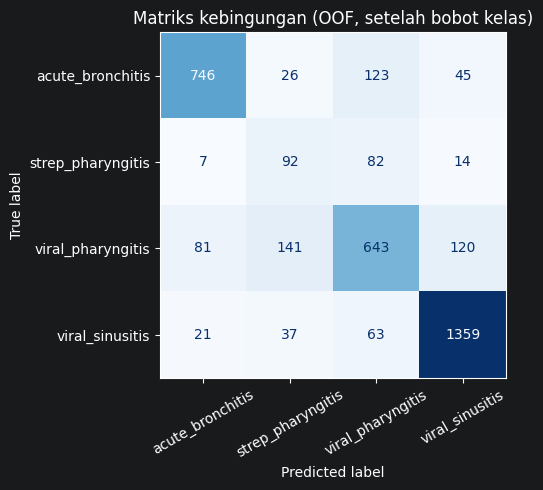

In [25]:
pred_oof = (P * w).argmax(1)
print(classification_report(y, pred_oof, target_names=classes, digits=3, zero_division=0))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(confusion_matrix(y, pred_oof), display_labels=classes).plot(
    ax=ax, cmap="Blues", xticks_rotation=30, colorbar=False)
ax.set_title("Matriks kebingungan (OOF, setelah bobot kelas)")
plt.tight_layout(); plt.show()

**Pengamatan.** `strep_pharyngitis` adalah kelas paling sulit (F1 0,375). Kesalahannya hampir seluruhnya terjadi dengan `viral_pharyngitis`, yaitu sesama infeksi tenggorokan: 82 kasus strep diprediksi viral, dan 141 kasus viral diprediksi strep. Itu sebabnya precision strep rendah. Gejala kedua kondisi ini memang sangat mirip. Data juga tidak memuat hasil tes strep (antigen cepat atau kultur) sama sekali, dan tes inilah yang biasanya membedakan keduanya secara klinis. Lihat bagian keterbatasan.

## 13. Model final dan submission

Model final dilatih ulang di seluruh data train. Jumlah iterasi diambil dari rata-rata fold, dinaikkan 10% karena data latihnya lebih banyak. Tiga seed dirata-rata untuk mengurangi variasi acak.

In [26]:
n_rounds = int(np.mean(best["iters"]) * 1.1)
params = dict(objective="multiclass", num_class=K, verbosity=-1, **best["cfg"])
print("Jumlah iterasi final:", n_rounds)

Pt = np.zeros((len(Xt), K))
imp = np.zeros(X.shape[1])
for seed in [1, 2, 3]:
    d = lgb.Dataset(X, y, weight=class_weights(y, K), categorical_feature=cats, free_raw_data=False)
    m = lgb.train({**params, "seed": seed}, d, num_boost_round=n_rounds)
    Pt += m.predict(Xt) / 3
    imp += m.feature_importance("gain") / 3

pred = np.array(classes)[(Pt * w).argmax(1)]
sub = pd.DataFrame({"sample_id": test_feat["sample_id"].values, "target_class": pred})

# Urutan submission harus sama dengan contoh dari panitia
ref = pd.read_csv(os.path.join(DATA_DIR, "sample_submission.csv"))[["sample_id"]]
sub = ref.merge(sub, on="sample_id", how="left", validate="one_to_one")
assert sub["target_class"].notna().all(), "ada sample_id tanpa prediksi"
assert len(sub) == len(ref) and sub["sample_id"].is_unique

sub_path = os.path.join(OUT_DIR, "submission.csv")
sub.to_csv(sub_path, index=False)
print("Disimpan:", sub_path, "|", sub.shape)
print("\nDistribusi prediksi test:")
print(sub["target_class"].value_counts(normalize=True).round(3).to_string())

Jumlah iterasi final: 327
Disimpan: C:\INAH-MINE\GEMASTIK-XIX\gdgoc_claude\output\submission.csv | (1400, 2)

Distribusi prediksi test:
target_class
viral_sinusitis      0.399
viral_pharyngitis    0.253
acute_bronchitis     0.247
strep_pharyngitis    0.101


## 14. Interpretasi

Kepentingan fitur (gain) menunjukkan sinyal mana yang paling dipakai model. Ini bukan bukti sebab-akibat, tetapi berguna untuk memeriksa apakah model belajar dari hal yang masuk akal.

10 fitur teratas menyumbang 47.1% total gain


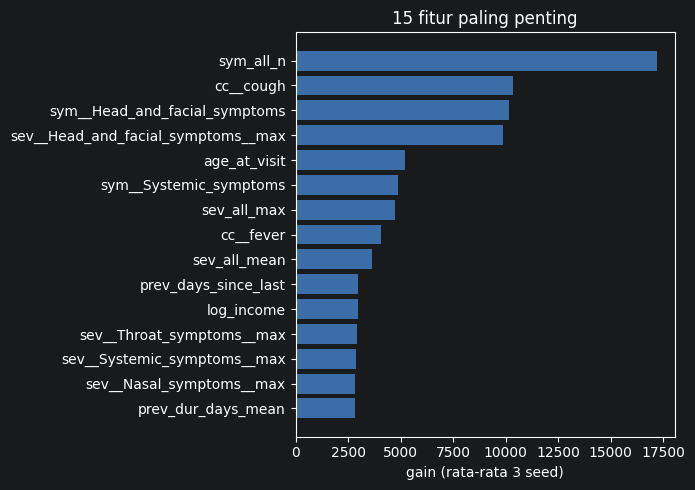

,fitur,gain,persen
0,sym_all_n,17196.515100,11.08
1,cc__cough,10343.246998,6.66
2,sym__Head_and_facial_symptoms,10180.621855,6.56
3,sev__Head_and_facial_symptoms__max,9894.078249,6.37
4,age_at_visit,5228.929108,3.37
5,sym__Systemic_symptoms,4872.370312,3.14
6,sev_all_max,4741.176192,3.05
7,cc__fever,4079.181832,2.63
8,sev_all_mean,3659.012957,2.36
9,prev_days_since_last,2979.485167,1.92


In [27]:
fi = pd.DataFrame({"fitur": X.columns, "gain": imp}).sort_values("gain", ascending=False).reset_index(drop=True)
fi["persen"] = (fi["gain"] / fi["gain"].sum() * 100).round(2)
print(f"10 fitur teratas menyumbang {fi.head(10)['persen'].sum():.1f}% total gain")

top = fi.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(top["fitur"], top["gain"], color="#3b6ea8")
ax.set_xlabel("gain (rata-rata 3 seed)")
ax.set_title("15 fitur paling penting")
plt.tight_layout(); plt.show()
fi.head(15)

**Interpretasi.** Fitur teratas adalah jumlah gejala triase, batuk, dan gejala kepala/wajah. Ini sejalan dengan logika klinis: gejala kepala dan wajah berkaitan dengan sinusitis, sedangkan batuk lebih sering pada bronkitis.

## 15. Keterbatasan dan asumsi

Bagian ini mencatat hal-hal yang belum diverifikasi, supaya pembaca bisa menilai hasilnya dengan tepat.

1. **Keluhan utama tanpa timestamp.** `presenting_complaints` tidak punya waktu. Diasumsikan dicatat saat triase. Asumsi ini masuk akal tetapi belum bisa dibuktikan dari data.
2. **Hasil tes strep tidak tersedia.** Tidak ada observasi antigen cepat atau kultur di data. Ini kemungkinan pembatas utama untuk kelas `strep_pharyngitis`, karena pembedaan klinisnya biasanya bergantung pada tes tersebut.
3. **Rentang nilai klinis** berasal dari pengetahuan umum, bukan dokumen resmi. Nilai di luar rentang dijadikan `NaN`, tetapi batasnya bisa sedikit berbeda dari standar tertentu.
4. **Satuan `Body Height`** belum jelas karena campur antara meter dan sentimeter. Kolom ini tidak diberi rentang.
5. **Skor OOF sedikit optimistik.** Early stopping memakai fold validasi, dan bobot kelas dituning di atas OOF. Split-half memberi perkiraan yang lebih jujur, tetapi tetap ada ketidakpastian.
6. **Batas bobot `strep_pharyngitis`** mentok di 2,0. Grid yang lebih lebar belum diuji.
7. **Tidak ada seleksi fitur.** Semua fitur dipakai. Seleksi bisa menambah optimisme jika dilakukan berdasarkan CV.
8. **Skor leaderboard** bisa berbeda dari perkiraan karena test hanya memakai sebagian data uji, dan skor publik tidak mencerminkan skor privat.

## Lampiran: log keputusan

Semua keputusan pembersihan dan filter waktu tercatat di sini. Log ini bisa dijadikan tabel di laporan.

In [28]:
pd.DataFrame(DECISION_LOG).fillna("")

,table,time_col,mode,rows_in,kept,dropped,ts_unparsed,check,count,decision,rows,out_of_range_set_nan,bounds
0,triage_vitals,measured_at,strict(<cutoff),30000.0,0.0,30000.0,0.0,,,,,,
1,triage_vitals,measured_at,same-second(<cutoff+1s),30000.0,30000.0,0.0,0.0,,,,,,
2,triage_symptoms,observed_at,strict(<cutoff),19065.0,0.0,19065.0,0.0,,,,,,
3,triage_symptoms,observed_at,same-second(<cutoff+1s),19065.0,19065.0,0.0,0.0,,,,,,
4,triage_symptom_severity,observed_at,strict(<cutoff),16594.0,0.0,16594.0,0.0,,,,,,
5,triage_symptom_severity,observed_at,same-second(<cutoff+1s),16594.0,16594.0,0.0,0.0,,,,,,
6,conditions,recorded_at,strict(<cutoff),3583.0,3583.0,0.0,0.0,,,,,,
7,conditions,recorded_at,same-second(<cutoff+1s),3583.0,3583.0,0.0,0.0,,,,,,
8,observations,observed_at,strict(<cutoff),55648.0,55648.0,0.0,0.0,,,,,,
9,observations,observed_at,same-second(<cutoff+1s),55648.0,55648.0,0.0,0.0,,,,,,
